# Close Python. Reopen the same work.
Save context, observation and Job references, restart the kernel, then retrieve
the original result. This is a fresh Python process, not just a second variable.
The underlying model is the same small synthetic TEST field used in the other notebooks.

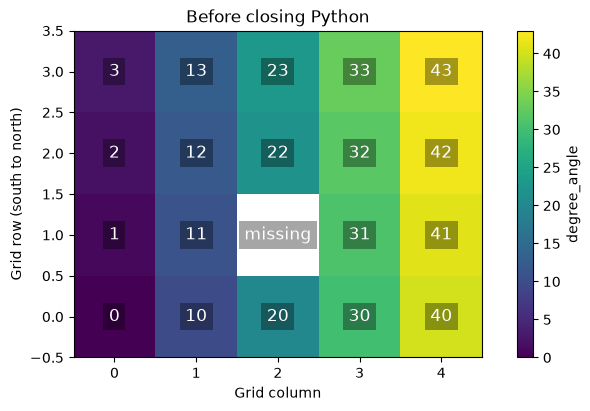

In [1]:
import json
import os
from pathlib import Path
from klab_client import connect, ObservationRequest, RectangularGeometry, save_handle
from notebook_setup import profile, certificate, track_session, reset_field, plot_grid

connection = connect(profile(), credentials=certificate())
client = connection.client
session = client.create_session(name="Notebook: return to saved work")
track_session(session)
context = session.create_context(configuration={"persistence": "EXPLICIT_ACTION"})
region = context.observe(ObservationRequest("earth:Region",
    geometry=RectangularGeometry(200000, 200500, 6000000, 6000400, 5, 4))).result(120)
focused = context.within(region)
reset_field()
job = focused.observe("geography:Aspect in degree_angle")
observation = job.result(120)
original_values = plot_grid(observation, title="Before closing Python")

## Save references, not credentials
The JSON file identifies the work on its original Runtime. The resolver Job is
also saved as its own kind of Job, not reinterpreted as an observation.

In [2]:
from IPython.display import display
from klab_client import ObservationImpl

save_handle(focused, "context.json")
save_handle(observation, "observation.json")
save_handle(job, "job.json")
resolver_capabilities = client.resolver.capabilities()
print("Resolver service:", resolver_capabilities.service_id)
resolver_job = client.resolver.resolve(ObservationImpl(urn="",
    observable=client.reasoner.resolve_observable("geography:Elevation in m")), focused)
assert isinstance(resolver_job.result(120), dict)
save_handle(resolver_job, "resolver.json")
display(json.loads(Path("observation.json").read_text()))
Path("checkpoint.json").write_text(json.dumps({"pid": os.getpid(), "session": session.id,
    "observation": observation.id, "job": job.id,
    "values": [str(v) if v is not None else None for v in original_values]}))
connection.close()
print("Local connection closed. The remote work is still retained.")

Resolver service: f3173a0e-15c7-4ca2-ba7e-91bb75835131


{'context_id': 'bf8ce938ea7243ad83d2bf877982b0e4.ivku31l88',
 'kind': 'observation',
 'observation_id': 561,
 'runtime_id': '8d3a8012-e57a-4956-8812-daa01cdb79ae',
 'runtime_url': 'http://127.0.0.1:8094/runtime',
 'scope': 'bf8ce938ea7243ad83d2bf877982b0e4.ivku31l88.557',
 'version': 1}

Local connection closed. The remote work is still retained.


## Restart the kernel, then run the cells below
The recording actually shuts down the first kernel and starts a new one here.
Credentials are acquired again; they do not come from a saved handle.

In [1]:
import json
import os
from pathlib import Path
import pandas as pd
from IPython.display import display
from klab_client import connect, load_handle, Session
from notebook_setup import profile, issued_token, plot_grid

before = json.loads(Path("checkpoint.json").read_text())
assert os.getpid() != before["pid"]
connection = connect(profile(), credentials=issued_token())
client = connection.client
requests = []
client.transport._http.event_hooks["request"].append(
    lambda request: requests.append((request.method, request.url.path)))
context = client.restore_handle(load_handle("context.json"))
observation = client.restore_handle(load_handle("observation.json"))
job = client.restore_handle(load_handle("job.json"))
resolver_job = client.restore_handle(load_handle("resolver.json"))
assert isinstance(resolver_job.result(120), dict) and resolver_job.service == "resolver"
assert observation.id == before["observation"] and job.id == before["job"]
assert job.result(120).id == observation.id and context.owned is False
display(pd.DataFrame([
    {"process": "Before restart", "PID": before["pid"], "observation": before["observation"], "Job": before["job"]},
    {"process": "After restart", "PID": os.getpid(), "observation": observation.id, "Job": job.id},
]))

,process,PID,observation,Job
0,Before restart,37996,561,71
1,After restart,34312,561,71


## Continue with the original values
No scientific submission is made while restoring and reading the saved work.

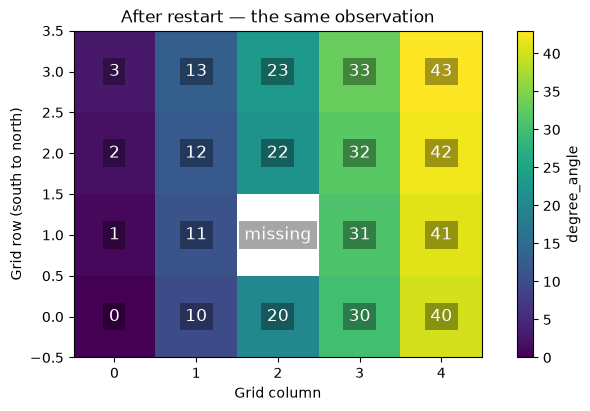

Scientific submissions since reopening: 0
Now the owner has explicitly released the example's remote session.


In [2]:
values = plot_grid(observation, title="After restart — the same observation")
assert [str(v) if v is not None else None for v in values] == before["values"]
submissions = [path for method, path in requests if path.endswith("/submit") or path.endswith("/resolve")]
assert submissions == []
print("Scientific submissions since reopening:", len(submissions))
assert Session(client, before["session"]).release()
connection.close()
print("Now the owner has explicitly released the example's remote session.")